# FULFILLMENT PULSE — 02 | Delivery-Time Prediction & Model Evaluation

**Business question:** Can we estimate total food-delivery time using operational information available around order assignment, before the delivery is completed?

**Project objective:** Build and evaluate a reproducible regression workflow, compare a simple baseline with machine-learning models, explain prediction errors, and export outputs for the Power BI dashboard.

**Dataset:** Publicly shared Food Delivery dataset mirrored at `aneesarom/Food-Delivery` on Hugging Face and attributed to the Zomato Delivery Operations dataset on Kaggle. This is a third-party public dataset; it has **not** been independently verified as an official Zomato production-data release.

**Important continuity note:** Notebook 01 was a *data ingestion and quality audit*. It combined the source splits for descriptive inspection and exported a raw snapshot and quality report; it did not produce a cleaned modelling dataset. This notebook therefore reloads the source `train` and `test` splits separately, applies the documented cleaning and feature-engineering rules consistently, and keeps the source test split untouched until final evaluation.

**Prediction-time assumption:** We model an estimate made around order assignment, before the delivery is completed. We deliberately exclude `Time_Order_picked` because it is recorded after the order is placed and could introduce information that would not be available at the chosen prediction point. This is a modelling assumption for the portfolio project and should be stated in the README.

**Run environment:** Google Colab CPU is sufficient; no paid API key or GPU is required.

## 1. Install and import libraries

In [1]:
!pip -q install datasets pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
OUTPUT_DIR = Path('fulfillment_pulse_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Libraries imported. Output folder:', OUTPUT_DIR.resolve())

Libraries imported. Output folder: /content/fulfillment_pulse_outputs


## 2. Reload the original train and test splits

We use the source training split for model development and the source test split as a final holdout. A validation split will be created **only from the training split** for model selection. The source test split is not used to fit the preprocessing steps or choose the model.

In [3]:
dataset = load_dataset('aneesarom/Food-Delivery')

if 'train' not in dataset or 'test' not in dataset:
    raise ValueError(f"Expected 'train' and 'test' splits. Found: {list(dataset.keys())}")

train_raw = dataset['train'].to_pandas().copy()
test_raw = dataset['test'].to_pandas().copy()

target = 'Time_taken (min)'
required_columns = [
    'Delivery_person_Age', 'Delivery_person_Ratings',
    'Restaurant_latitude', 'Restaurant_longitude',
    'Delivery_location_latitude', 'Delivery_location_longitude',
    'Order_Date', 'Time_Orderd', 'Weather_conditions',
    'Road_traffic_density', 'Vehicle_condition', 'Type_of_order',
    'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', target
]
missing_columns = [c for c in required_columns if c not in train_raw.columns or c not in test_raw.columns]
if missing_columns:
    raise KeyError(f'Missing expected columns: {missing_columns}')

print(f'Train split: {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns')
print(f'Test split:  {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns')
print('Target missing in train:', train_raw[target].isna().sum())
print('Target missing in test: ', test_raw[target].isna().sum())

README.md:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.76MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  447kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/36467 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9117 [00:00<?, ? examples/s]

Train split: 36,467 rows × 20 columns
Test split:  9,117 rows × 20 columns
Target missing in train: 0
Target missing in test:  0


## 3. Cleaning and feature-engineering functions

### Data-treatment rules

- Text placeholders such as `NaN`, `None` and blank strings are standardized to missing values.
- Courier ages outside the chosen plausibility interval of 18–65 and ratings outside 1–5 are treated as missing, not deleted.
- `Vehicle_condition` is expected to use the source's 0, 1 and 2 levels; other values are treated as missing pending source clarification.
- Missing categorical values remain in the dataset and are imputed as `Unknown` inside the training pipeline.
- GPS coordinates are used only when both restaurant and customer coordinate pairs fall within broad India bounds (latitude 6–38, longitude 68–98). These are screening bounds, not precise geocoding.
- Distance is calculated using the Haversine formula. Invalid/missing coordinate pairs produce a missing distance plus a missingness indicator.
- `Time_Orderd` is parsed robustly to create cyclic order-hour and weekday features. `Time_Order_picked` is excluded from modelling to reduce post-order information leakage.
- IDs and raw coordinates are excluded from the predictors.

These are explicit project assumptions, not claims that every flagged value is factually wrong.

In [4]:
NULL_TOKENS = {'', 'nan', 'none', 'null', 'na', 'n/a'}

CATEGORICAL_COLUMNS = [
    'Weather_conditions', 'Road_traffic_density', 'Type_of_order',
    'Type_of_vehicle', 'Festival', 'City'
]

NUMERIC_COLUMNS = [
    'Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition',
    'multiple_deliveries', 'distance_km', 'distance_missing',
    'order_hour_sin', 'order_hour_cos', 'order_dow_sin', 'order_dow_cos'
]
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS


def normalize_text(series):
    """Trim text and standardize missing values for scikit-learn compatibility.

    pandas StringDtype uses pd.NA, which can cause some scikit-learn imputers
    to raise: TypeError: boolean value of NA is ambiguous. Return an object
    Series with np.nan instead, which SimpleImputer handles consistently.
    """
    out = series.astype('string').str.strip()
    out = out.mask(out.str.lower().isin(NULL_TOKENS))
    return out.astype(object).where(out.notna(), np.nan)


def parse_clock_to_minutes(value):
    """Parse clock strings such as 09:20, 24:10:00, or fractional-day values."""
    if pd.isna(value):
        return np.nan
    s = str(value).strip()
    if s.lower() in NULL_TOKENS:
        return np.nan

    # Some rows encode time as a fraction of a day (e.g. 0.9583333).
    try:
        numeric_value = float(s)
        if 0 <= numeric_value < 1:
            return float(numeric_value * 24 * 60)
    except (TypeError, ValueError):
        pass

    match = re.match(r'^(\d{1,2}):(\d{1,2})(?::(\d{1,2}))?$', s)
    if not match:
        return np.nan

    hour = int(match.group(1))
    minute = int(match.group(2))
    second = int(match.group(3) or 0)
    if minute > 59 or second > 59 or hour > 24 or (hour == 24 and (minute > 0 or second > 0)):
        # The source contains occasional hour-24 clock values; preserve their
        # clock-of-day meaning by allowing 24:xx only if it is a valid next-day stamp.
        if hour != 24 or minute > 59 or second > 59:
            return np.nan
    return hour * 60 + minute + second / 60


def haversine_km(lat1, lon1, lat2, lon2):
    """Vectorized great-circle distance in kilometres."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def prepare_model_frame(source_df, split_name='data'):
    """Apply consistent cleaning and produce only documented model features + target."""
    data = source_df.copy()

    # Normalize categorical/text-like columns.
    text_columns = [c for c in CATEGORICAL_COLUMNS + ['Order_Date', 'Time_Orderd'] if c in data.columns]
    for col in text_columns:
        data[col] = normalize_text(data[col])

    # Standardize one known spelling variation while retaining the original meaning.
    if 'City' in data.columns:
        data['City'] = data['City'].replace({'Metropolitian': 'Metropolitan'})

    # Convert numerics safely.
    for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition',
                'multiple_deliveries', 'Restaurant_latitude', 'Restaurant_longitude',
                'Delivery_location_latitude', 'Delivery_location_longitude', target]:
        data[col] = pd.to_numeric(data[col], errors='coerce')

    # Plausibility rules: mark questionable values missing rather than dropping rows.
    data.loc[~data['Delivery_person_Age'].between(18, 65), 'Delivery_person_Age'] = np.nan
    data.loc[~data['Delivery_person_Ratings'].between(1, 5), 'Delivery_person_Ratings'] = np.nan
    data.loc[~data['Vehicle_condition'].isin([0, 1, 2]), 'Vehicle_condition'] = np.nan
    data.loc[~data['multiple_deliveries'].between(0, 3), 'multiple_deliveries'] = np.nan

    # Validate coordinates using broad India screening bounds.
    rlat = data['Restaurant_latitude']
    rlon = data['Restaurant_longitude']
    dlat = data['Delivery_location_latitude']
    dlon = data['Delivery_location_longitude']
    restaurant_ok = rlat.between(6, 38) & rlon.between(68, 98)
    customer_ok = dlat.between(6, 38) & dlon.between(68, 98)
    coordinate_pair_ok = restaurant_ok & customer_ok

    distance = pd.Series(np.nan, index=data.index, dtype='float64')
    valid_idx = coordinate_pair_ok.fillna(False)
    if valid_idx.any():
        distance.loc[valid_idx] = haversine_km(
            rlat.loc[valid_idx].to_numpy(), rlon.loc[valid_idx].to_numpy(),
            dlat.loc[valid_idx].to_numpy(), dlon.loc[valid_idx].to_numpy()
        )

    # Flag very long calculated distances for audit; do not silently delete them.
    data['distance_over_100km_flag'] = (distance > 100).astype('int8')
    # Treat >100 km as unusable for a local food-delivery distance estimate.
    distance = distance.mask(distance > 100)
    data['distance_km'] = distance
    data['distance_missing'] = data['distance_km'].isna().astype('int8')

    # Time features from order time only. The picked-time field is deliberately excluded.
    order_minutes = data['Time_Orderd'].apply(parse_clock_to_minutes)
    order_minutes_mod = order_minutes % (24 * 60)
    order_hour = np.floor(order_minutes_mod / 60)

    order_date = pd.to_datetime(data['Order_Date'], format='%d-%m-%Y', errors='coerce')
    order_dow = order_date.dt.dayofweek.astype('float')

    data['order_hour_sin'] = np.sin(2 * np.pi * order_hour / 24)
    data['order_hour_cos'] = np.cos(2 * np.pi * order_hour / 24)
    data['order_dow_sin'] = np.sin(2 * np.pi * order_dow / 7)
    data['order_dow_cos'] = np.cos(2 * np.pi * order_dow / 7)

    # Keep only predictors and the target. Do not expose IDs/raw timestamps/coordinates.
    modelling = data[FEATURE_COLUMNS + [target]].copy()
    modelling = modelling.loc[modelling[target].notna() & (modelling[target] > 0)].copy()

    # Final compatibility guard: ensure categorical missing values are np.nan,
    # not pandas.NA, before the frames enter scikit-learn pipelines.
    for col in CATEGORICAL_COLUMNS:
        modelling[col] = modelling[col].astype(object)
        modelling[col] = modelling[col].where(modelling[col].notna(), np.nan)

    print(f'{split_name}: {len(source_df):,} source rows -> {len(modelling):,} modelling rows')
    print(f'  Missing route distance: {modelling["distance_missing"].mean():.1%}')
    print(f'  Missing order-hour features: {modelling["order_hour_sin"].isna().mean():.1%}')
    print(f'  Target mean: {modelling[target].mean():.2f} min | median: {modelling[target].median():.1f} min')
    return modelling

## 4. Prepare train and final holdout datasets

In [5]:
train_model = prepare_model_frame(train_raw, 'Source train')
test_model = prepare_model_frame(test_raw, 'Source test holdout')

X = train_model[FEATURE_COLUMNS]
y = train_model[target].astype(float)
X_test = test_model[FEATURE_COLUMNS]
y_test = test_model[target].astype(float)

print('\nFeature count:', len(FEATURE_COLUMNS))
print('Numeric features:', NUMERIC_COLUMNS)
print('Categorical features:', CATEGORICAL_COLUMNS)

Source train: 36,467 source rows -> 36,467 modelling rows
  Missing route distance: 8.9%
  Missing order-hour features: 4.8%
  Target mean: 26.29 min | median: 26.0 min
Source test holdout: 9,117 source rows -> 9,117 modelling rows
  Missing route distance: 8.9%
  Missing order-hour features: 4.6%
  Target mean: 26.29 min | median: 26.0 min

Feature count: 16
Numeric features: ['Delivery_person_Age', 'Delivery_person_Ratings', 'Vehicle_condition', 'multiple_deliveries', 'distance_km', 'distance_missing', 'order_hour_sin', 'order_hour_cos', 'order_dow_sin', 'order_dow_cos']
Categorical features: ['Weather_conditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']


## 5. Quick diagnostic: engineered distance and target

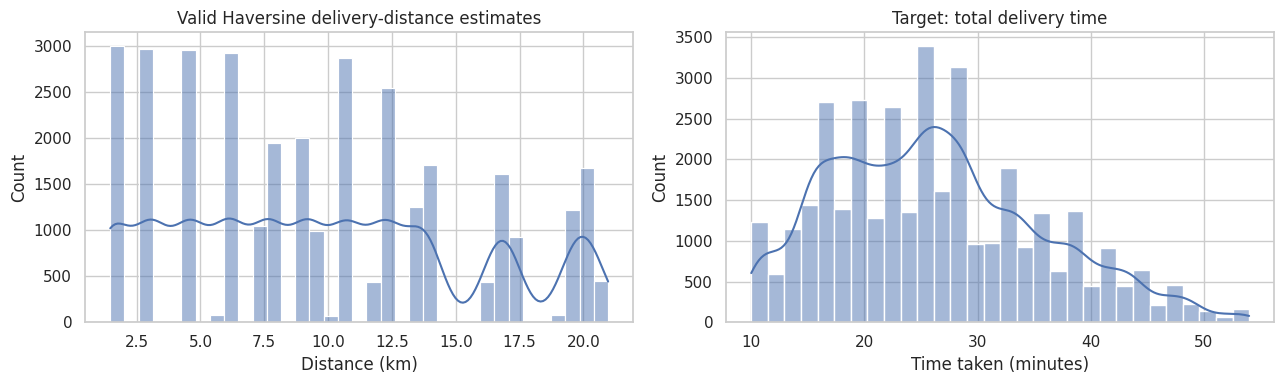

,count,mean,std,min,25%,50%,75%,max
distance_km,33207.0,9.727066,5.609633,1.465067,4.657672,9.193028,13.680987,20.969489
Time_taken (min),36467.0,26.293772,9.384628,10.000000,19.000000,26.000000,32.000000,54.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(train_model['distance_km'].dropna(), bins=35, kde=True, ax=axes[0])
axes[0].set_title('Valid Haversine delivery-distance estimates')
axes[0].set_xlabel('Distance (km)')

sns.histplot(y, bins=30, kde=True, ax=axes[1])
axes[1].set_title('Target: total delivery time')
axes[1].set_xlabel('Time taken (minutes)')

plt.tight_layout()
plt.show()

display(train_model[['distance_km', target]].describe().T)

## 6. Create a validation split from the training data

The source `test` split remains untouched until the final evaluation. We split only the source `train` data into model-training and validation subsets. The validation subset is used to compare candidate models and choose one model family.

In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Model training rows: {len(X_train):,}')
print(f'Validation rows:     {len(X_valid):,}')
print(f'Final test rows:     {len(X_test):,} (kept separate)')

Model training rows: 29,173
Validation rows:     7,294
Final test rows:     9,117 (kept separate)


## 7. Build a preprocessing pipeline

Preprocessing is fitted **inside each model pipeline**, using only the model-training partition. This prevents validation/test information from leaking into imputers, scaling or category encoding.

In [8]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_transformer, NUMERIC_COLUMNS),
        ('categorical', categorical_transformer, CATEGORICAL_COLUMNS)
    ],
    remainder='drop',
    sparse_threshold=0  # Keep the transformed matrix dense for the candidate estimators.
)

print('Preprocessing pipeline configured.')

Preprocessing pipeline configured.


## 8. Train baseline and candidate regression models

We compare a mean-prediction baseline with three models of increasing flexibility:

1. **Dummy Regressor:** establishes the minimum benchmark a useful model should beat.
2. **Ridge Regression:** a regularized linear baseline.
3. **Random Forest Regressor:** captures nonlinear relationships and feature interactions.
4. **HistGradientBoosting Regressor:** a boosting model for nonlinear tabular data.

We select the candidate with the lowest validation MAE. Hyperparameters are intentionally moderate to keep the notebook practical on a Colab CPU.

In [9]:
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Ridge regression': Ridge(alpha=2.0),
    'Random forest': RandomForestRegressor(
        n_estimators=180, max_depth=18, min_samples_leaf=2,
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        max_iter=180, learning_rate=0.08, max_leaf_nodes=25,
        l2_regularization=1.0, random_state=RANDOM_STATE,
        early_stopping=True, validation_fraction=0.1
    )
}

trained_pipelines = {}
validation_rows = []

for model_name, estimator in models.items():
    print(f'Training: {model_name} ...')
    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', estimator)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.time() - start
    predictions = pipeline.predict(X_valid)

    mae = mean_absolute_error(y_valid, predictions)
    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    r2 = r2_score(y_valid, predictions)

    trained_pipelines[model_name] = pipeline
    validation_rows.append({
        'model': model_name,
        'MAE_minutes': mae,
        'RMSE_minutes': rmse,
        'R2': r2,
        'fit_seconds': fit_seconds
    })
    print(f'  MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f} | fit={fit_seconds:.1f}s')

validation_results = pd.DataFrame(validation_rows).sort_values('MAE_minutes').reset_index(drop=True)
print('\nValidation model comparison:')
display(validation_results.round(3))

Training: Mean baseline ...
  MAE=7.527 | RMSE=9.393 | R²=-0.000 | fit=0.3s
Training: Ridge regression ...
  MAE=4.829 | RMSE=6.081 | R²=0.581 | fit=0.3s
Training: Random forest ...
  MAE=3.229 | RMSE=4.095 | R²=0.810 | fit=39.7s
Training: HistGradientBoosting ...
  MAE=3.211 | RMSE=4.037 | R²=0.815 | fit=2.3s

Validation model comparison:


,model,MAE_minutes,RMSE_minutes,R2,fit_seconds
0,HistGradientBoosting,3.211,4.037,0.815,2.272
1,Random forest,3.229,4.095,0.810,39.739
2,Ridge regression,4.829,6.081,0.581,0.268
3,Mean baseline,7.527,9.393,-0.000,0.287


## 9. Compare validation performance

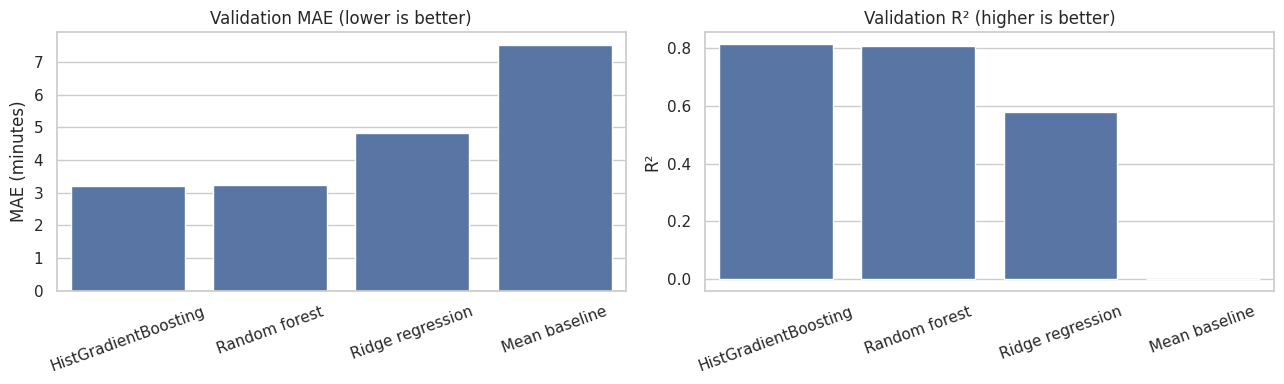

Selected model based on lowest validation MAE: HistGradientBoosting


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=validation_results, x='model', y='MAE_minutes', ax=axes[0])
axes[0].set_title('Validation MAE (lower is better)')
axes[0].set_xlabel('')
axes[0].set_ylabel('MAE (minutes)')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=validation_results, x='model', y='R2', ax=axes[1])
axes[1].set_title('Validation R² (higher is better)')
axes[1].set_xlabel('')
axes[1].set_ylabel('R²')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

best_model_name = validation_results.iloc[0]['model']
print('Selected model based on lowest validation MAE:', best_model_name)

## 10. Inspect validation residuals

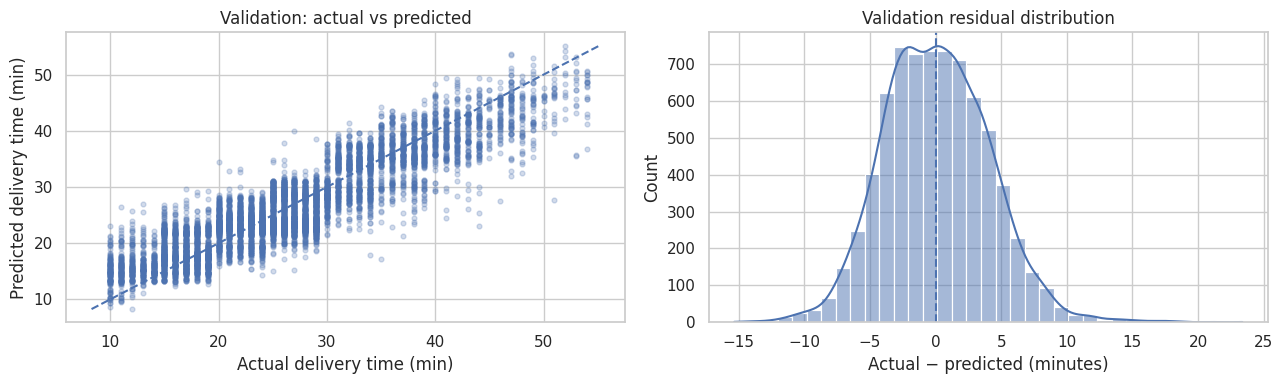

In [11]:
best_validation_pipeline = trained_pipelines[best_model_name]
valid_predictions = best_validation_pipeline.predict(X_valid)
valid_residuals = y_valid.to_numpy() - valid_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(y_valid, valid_predictions, alpha=0.25, s=12)
minimum = min(float(y_valid.min()), float(valid_predictions.min()))
maximum = max(float(y_valid.max()), float(valid_predictions.max()))
axes[0].plot([minimum, maximum], [minimum, maximum], linestyle='--')
axes[0].set_title('Validation: actual vs predicted')
axes[0].set_xlabel('Actual delivery time (min)')
axes[0].set_ylabel('Predicted delivery time (min)')

sns.histplot(valid_residuals, bins=35, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle='--')
axes[1].set_title('Validation residual distribution')
axes[1].set_xlabel('Actual − predicted (minutes)')

plt.tight_layout()
plt.show()

## 11. Check errors across operational conditions

Aggregate model error by traffic and weather. These comparisons are descriptive: a larger error in a group does not by itself prove that the category causes poor predictions. Groups with very few rows are excluded from the displayed table.

In [12]:
validation_diagnostics = X_valid.copy()
validation_diagnostics['actual_minutes'] = y_valid.to_numpy()
validation_diagnostics['predicted_minutes'] = valid_predictions
validation_diagnostics['absolute_error_minutes'] = np.abs(
    validation_diagnostics['actual_minutes'] - validation_diagnostics['predicted_minutes']
)

for group_col in ['Road_traffic_density', 'Weather_conditions', 'City']:
    group_summary = (
        validation_diagnostics.groupby(group_col, dropna=False)
        .agg(
            orders=('actual_minutes', 'size'),
            mean_actual_minutes=('actual_minutes', 'mean'),
            mean_absolute_error=('absolute_error_minutes', 'mean')
        )
        .query('orders >= 30')
        .sort_values('mean_absolute_error', ascending=False)
    )
    print(f'\nError by {group_col}:')
    display(group_summary.round(2))


Error by Road_traffic_density:


,orders,mean_actual_minutes,mean_absolute_error
Road_traffic_density,,,
NaN,108,24.89,6.48
Jam,2229,31.32,3.56
High,704,27.27,3.40
Medium,1763,26.74,3.11
Low,2490,21.38,2.77



Error by Weather_conditions:


,orders,mean_actual_minutes,mean_absolute_error
Weather_conditions,,,
NaN,108,24.89,6.48
Sandstorms,1213,25.94,3.41
Stormy,1215,25.64,3.28
Windy,1195,26.05,3.27
Sunny,1158,22.12,3.12
Cloudy,1195,29.34,2.96
Fog,1210,28.88,2.93



Error by City:


,orders,mean_actual_minutes,mean_absolute_error
City,,,
NaN,200,22.26,3.52
Metropolitan,5427,27.47,3.21
Urban,1644,22.75,3.19


## 12. Refit the selected model and evaluate once on the source test split

After selecting the model using validation MAE, we refit that model on the full source training split. We then evaluate it once on the separate source test split. Report these final test metrics in the project README and resume only after this cell has run successfully.

In [13]:
selected_estimator = clone(models[best_model_name])
final_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', selected_estimator)
])

start = time.time()
final_pipeline.fit(X, y)
final_fit_seconds = time.time() - start

test_predictions = final_pipeline.predict(X_test)
final_mae = mean_absolute_error(y_test, test_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
final_r2 = r2_score(y_test, test_predictions)

final_metrics = pd.DataFrame([{
    'selected_model': best_model_name,
    'test_MAE_minutes': final_mae,
    'test_RMSE_minutes': final_rmse,
    'test_R2': final_r2,
    'final_fit_seconds': final_fit_seconds,
    'train_rows': len(X),
    'test_rows': len(X_test)
}])

print('FINAL HOLDOUT TEST RESULTS')
display(final_metrics.round(3))

FINAL HOLDOUT TEST RESULTS


,selected_model,test_MAE_minutes,test_RMSE_minutes,test_R2,final_fit_seconds,train_rows,test_rows
0,HistGradientBoosting,3.154,3.981,0.82,2.561,36467,9117


## 13. Visualize final test-set performance

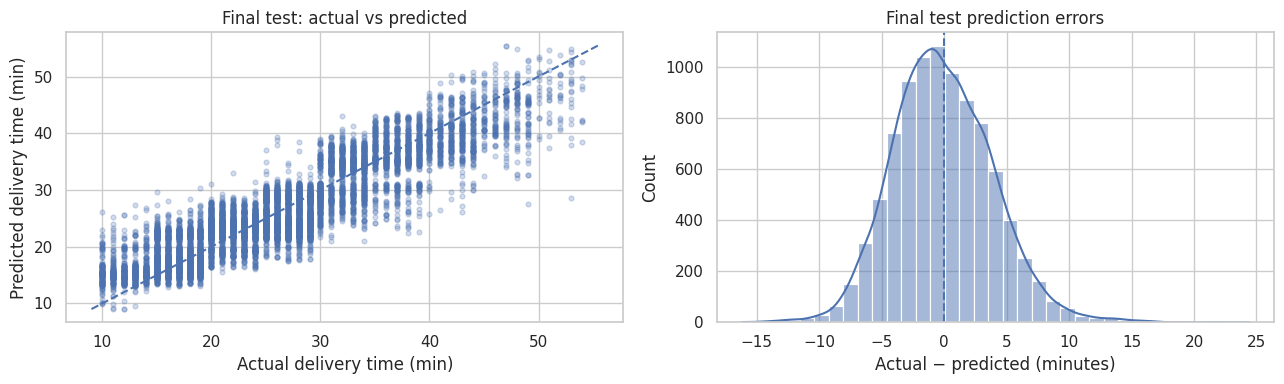

Median absolute error: 2.68 minutes
90th percentile absolute error: 6.35 minutes


In [14]:
final_predictions_df = X_test.copy()
final_predictions_df['actual_minutes'] = y_test.to_numpy()
final_predictions_df['predicted_minutes'] = test_predictions
final_predictions_df['error_minutes'] = (
    final_predictions_df['actual_minutes'] - final_predictions_df['predicted_minutes']
)
final_predictions_df['absolute_error_minutes'] = final_predictions_df['error_minutes'].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(final_predictions_df['actual_minutes'], final_predictions_df['predicted_minutes'], alpha=0.25, s=12)
lo = min(final_predictions_df['actual_minutes'].min(), final_predictions_df['predicted_minutes'].min())
hi = max(final_predictions_df['actual_minutes'].max(), final_predictions_df['predicted_minutes'].max())
axes[0].plot([lo, hi], [lo, hi], linestyle='--')
axes[0].set_title('Final test: actual vs predicted')
axes[0].set_xlabel('Actual delivery time (min)')
axes[0].set_ylabel('Predicted delivery time (min)')

sns.histplot(final_predictions_df['error_minutes'], bins=35, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle='--')
axes[1].set_title('Final test prediction errors')
axes[1].set_xlabel('Actual − predicted (minutes)')

plt.tight_layout()
plt.show()

print('Median absolute error:', round(final_predictions_df['absolute_error_minutes'].median(), 2), 'minutes')
print('90th percentile absolute error:', round(final_predictions_df['absolute_error_minutes'].quantile(0.90), 2), 'minutes')

## 14. Explain the model with permutation importance

Permutation importance measures how much the selected model's test-set MAE worsens when one input feature is shuffled. We compute it on a reproducible sample of the holdout data to keep runtime reasonable. It describes model reliance, not causation.

,feature,importance_mean,importance_std
10,Weather_conditions,1.8183,0.0450
11,Road_traffic_density,1.7806,0.0261
1,Delivery_person_Ratings,1.3525,0.0096
4,distance_km,1.3155,0.0603
0,Delivery_person_Age,1.2361,0.0238
2,Vehicle_condition,0.9866,0.0246
3,multiple_deliveries,0.5838,0.0340
14,Festival,0.1765,0.0139
15,City,0.0768,0.0023
5,distance_missing,0.0397,0.0068


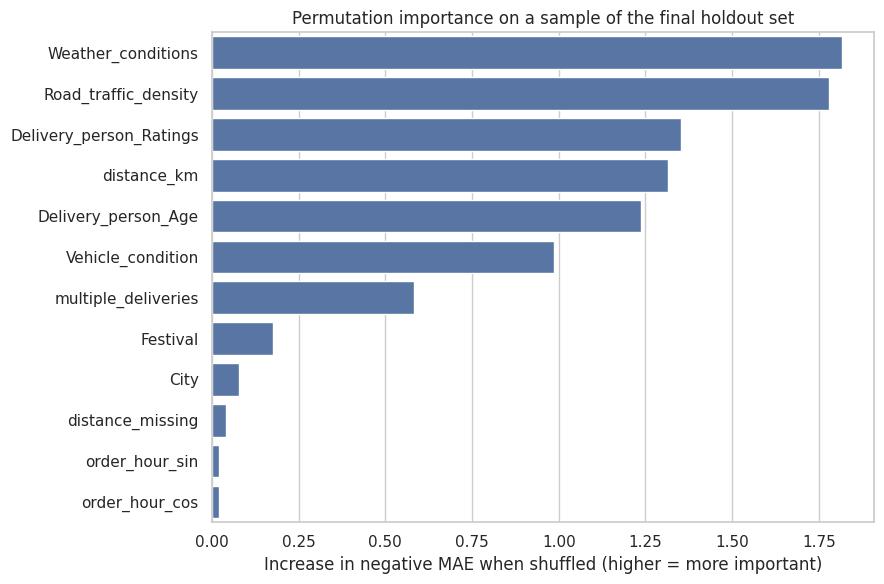

In [15]:
importance_sample_size = min(2500, len(X_test))
importance_sample = X_test.sample(n=importance_sample_size, random_state=RANDOM_STATE)
importance_target = y_test.loc[importance_sample.index]

perm = permutation_importance(
    final_pipeline,
    importance_sample,
    importance_target,
    scoring='neg_mean_absolute_error',
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)

display(importance_df.head(15).round(4))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(12), x='importance_mean', y='feature')
plt.title('Permutation importance on a sample of the final holdout set')
plt.xlabel('Increase in negative MAE when shuffled (higher = more important)')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 15. Export model, metrics and dashboard-ready predictions

In [16]:
model_path = OUTPUT_DIR / 'fulfillment_pulse_eta_model.joblib'
metrics_path = OUTPUT_DIR / 'fulfillment_pulse_model_metrics.csv'
validation_path = OUTPUT_DIR / 'fulfillment_pulse_validation_comparison.csv'
predictions_path = OUTPUT_DIR / 'fulfillment_pulse_test_predictions.csv'
importance_path = OUTPUT_DIR / 'fulfillment_pulse_permutation_importance.csv'

joblib.dump(final_pipeline, model_path)
final_metrics.to_csv(metrics_path, index=False)
validation_results.to_csv(validation_path, index=False)
final_predictions_df.to_csv(predictions_path, index=False)
importance_df.to_csv(importance_path, index=False)

print('Saved files:')
for path in [model_path, metrics_path, validation_path, predictions_path, importance_path]:
    print(f' - {path} ({path.stat().st_size:,} bytes)')

Saved files:
 - fulfillment_pulse_outputs/fulfillment_pulse_eta_model.joblib (526,706 bytes)
 - fulfillment_pulse_outputs/fulfillment_pulse_model_metrics.csv (204 bytes)
 - fulfillment_pulse_outputs/fulfillment_pulse_validation_comparison.csv (411 bytes)
 - fulfillment_pulse_outputs/fulfillment_pulse_test_predictions.csv (1,918,657 bytes)
 - fulfillment_pulse_outputs/fulfillment_pulse_permutation_importance.csv (950 bytes)


## 16. Analyst interpretation — complete after running

Use the actual outputs above to answer these questions. Do not invent performance figures or causal claims.

1. Which model had the lowest validation MAE?
2. How much did it improve on the mean baseline in MAE?
3. What were the final holdout MAE, RMSE and R²?
4. What does the MAE mean in practical delivery-time terms?
5. Which three features had the highest permutation importance?
6. Did error differ across traffic or weather groups?
7. What are the main limitations of this dataset and modelling setup?

### Limitations to disclose

- The dataset is a third-party public dataset attributed to Zomato; it is not verified internal company data.
- The prediction-time assumption is around order assignment. `Time_Order_picked` is excluded to reduce post-order leakage.
- Broad India coordinate bounds and the 100 km distance screen are project heuristics; they are not precise address validation.
- Historical dataset performance does not guarantee performance on current live deliveries or other cities/platforms.
- Feature importance is not causal evidence. A stakeholder would need operational experiments or stronger observational analysis to establish causes.
- This model estimates total delivery duration; it should not be described as a guaranteed live ETA service.

## 17. Download project outputs from Colab

In [17]:
# Optional: zip the generated artifacts so they can be downloaded together.
import shutil
zip_path = shutil.make_archive('fulfillment_pulse_outputs', 'zip', OUTPUT_DIR)
print('Created:', zip_path)

# In Google Colab, uncomment the following two lines to trigger a browser download:
# from google.colab import files
# files.download(zip_path)

Created: /content/fulfillment_pulse_outputs.zip
